In [175]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse import csr_matrix
import random
from IPython.display import SVG, display
from sknetwork.hierarchy import Paris, cut_straight, LouvainHierarchy, cut_balanced
from sknetwork.clustering import Louvain
from sknetwork.visualization import svg_graph, svg_bigraph, svg_dendrogram
import pandas as pd
from netgraph import Graph
from community_layout.layout_class import CommunityLayout
import matplotlib
from mycolorpy import colorlist as mcp
matplotlib.rcParams['figure.dpi'] = 100
random.seed(42)
np.random.seed(42)

In [3]:
# Finanses
df_fin = pd.read_csv('../data preprocessing and plotting/FINANSES_dataset.csv')
df_fin = df_fin.groupby(["Country","Partner"], sort=False, as_index=False).agg({"Value":"sum"})
g1 = nx.Graph()
for i, row in df_fin.iterrows():
    if row['Value'] != 0 and row['Country'] != row['Partner']:
        g1.add_edge(row['Country'], row['Partner'], weight=row['Value'])

In [5]:
# Organizations
df_org = pd.read_csv("../data preprocessing and plotting/ORGANIZATIONS_dataset.csv")
g2 = nx.Graph()
for i, row in df_org.iterrows():
    if not g2.has_edge(row['country1'], row['country2']):
        g2.add_edge(row['country1'], row['country2'], weight=row['degree'])

c:\Users\Wojtek\.conda\envs\tass\lib\site-packages\netgraph\_utils.py:360: RuntimeWarning: invalid value encountered in divide
  v = v / np.linalg.norm(v, axis=-1)[:, None] # unit vector


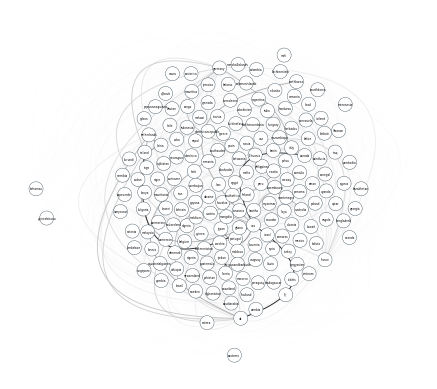

In [6]:
random.seed(42)
g1_pos = {node: (random.randint(0,10000)/10000,random.randint(0,10000)/10000) for node in g1.nodes()}
Graph(g1, node_layout='spring',
node_layout_kwargs={"node_positions": g1_pos},
node_labels=True,
edge_width=0.25,
node_size=2,
node_label_fontdict={'size': 2},
node_edge_width=0.1,
edge_layout='arc',
edge_alpha=1
)
plt.show()

In [ ]:
random.seed(42)
g2_pos = {node: (random.randint(0,10000)/10000,random.randint(0,10000)/10000) for node in g2.nodes()}
Graph(g2, node_layout='spring',
node_layout_kwargs={"node_positions": g2_pos},
node_labels=True,
edge_width=0.25,
node_size=2,
node_label_fontdict={'size': 2},
node_edge_width=0.1,
edge_layout='straight',
edge_alpha=1
)
plt.show()

In [193]:
def clustering(graph, n_clusters, chosen_alg, res):
    if chosen_alg == 'paris':
        alg = Paris()
    elif chosen_alg == 'louvain':
        alg = LouvainHierarchy(resolution=res)
    dendrogram = alg.fit_predict(nx.adjacency_matrix(graph).toarray())
    if chosen_alg == 'louvain':
        image = svg_dendrogram(dendrogram, names=list(graph.nodes), width=600)
    elif chosen_alg == 'paris':
        image = svg_dendrogram(dendrogram, names=list(graph.nodes), width=600, n_clusters=n_clusters)
    display(SVG(image))
    return cut_straight(dendrogram, n_clusters=n_clusters)

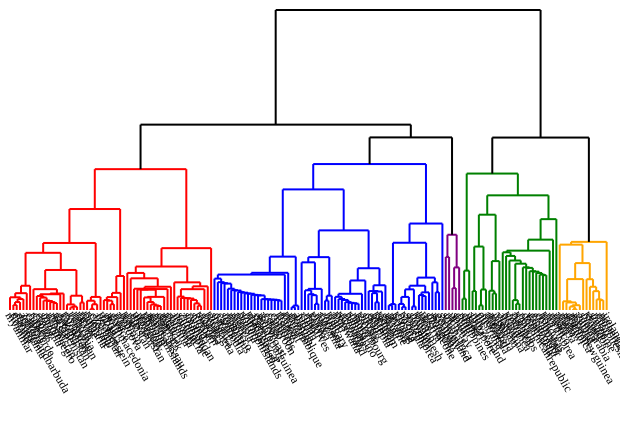

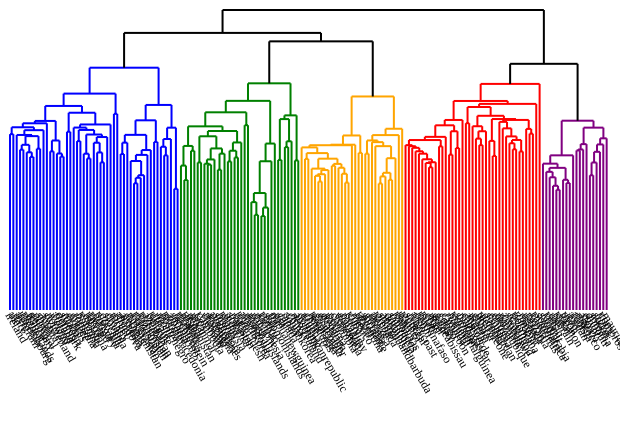

In [194]:
n_clusters_g1 = 5
n_clusters_g2 = 5
labels1 = clustering(g1, n_clusters_g1, 'paris', 1.3)
labels2 = clustering(g2, n_clusters_g2, 'paris', 1.1)
n_clusters_g1 = len(np.unique(labels1))
n_clusters_g2 = len(np.unique(labels2))

In [ ]:
cmap1 = mcp.gen_color(cmap="Set1",n=n_clusters_g1)
Graph(g1, node_layout='spring',
node_labels=True,
node_layout_kwargs={'node_positions': g1_pos},
node_color={node: cmap1[clas] for node, clas in zip(g1.nodes(), labels1)},
edge_width=0.25,
node_size=2,
node_label_fontdict={'size': 2},
node_edge_width=0.1,
edge_layout='arc',
edge_alpha=1)
plt.show()

In [ ]:
cmap2 = mcp.gen_color(cmap="Set1",n=n_clusters_g2)
Graph(g2, node_layout='spring',
node_labels=True,
node_layout_kwargs={'node_positions': g2_pos},
node_color={node: cmap2[clas] for node, clas in zip(g2.nodes(), labels2)},
edge_width=0.25,
node_size=2,
node_label_fontdict={'size': 2},
node_edge_width=0.1,
edge_layout='straight',
edge_alpha=1)
plt.show()

In [ ]:
Graph(g1,
      node_labels=True,
      node_color={node: cmap1[clas] for node, clas in zip(g1.nodes(), labels1)},
      node_layout='community', node_layout_kwargs={'node_to_community': {node: label for node, label in zip(g1.nodes(), labels1)}},
      edge_layout='arc', edge_layout_kwargs=dict(k=2000),
      edge_width=0.25,
      node_size=2,
      node_label_fontdict={'size': 2},
      node_edge_width=0.1,
      edge_alpha=1
)

In [ ]:
Graph(g2,
      node_labels=True,
      node_color={node: cmap2[clas] for node, clas in zip(g2.nodes(), labels2)},
      node_layout='community', node_layout_kwargs={'node_to_community': {node: label for node, label in zip(g2.nodes(), labels2)}},
      edge_layout='straight', edge_layout_kwargs=dict(k=2000),
      edge_width=0.25,
      node_size=2,
      node_label_fontdict={'size': 2},
      node_edge_width=0.1,
      edge_alpha=1
)

In [189]:
def jaccard_similarity(set1, set2):
    c = set1.intersection(set2)
    d = set1.union(set2)
    return len(c) / len(d)

In [190]:
def cluster_similarity_report(g1, g2, g1_n_clusters, g2_n_clusters, g1_labels, g2_labels):
    g1_clusters = [set() for _ in range(g1_n_clusters)]
    g2_clusters = [set() for _ in range(g2_n_clusters)]
    for node, clas in zip(g1.nodes, g1_labels):
        g1_clusters[clas].add(node)
    for node, clas in zip(g2.nodes, g2_labels):
        g2_clusters[clas].add(node)
    similarities = np.zeros((g1_n_clusters, g2_n_clusters))
    for i, g1_cluster in enumerate(g1_clusters):
        for j, g2_cluster in enumerate(g2_clusters):
            sim = jaccard_similarity(g1_cluster, g2_cluster)
            similarities[i, j] = sim
    return similarities, g1_clusters, g2_clusters


Text(50.722222222222214, 0.5, 'g1')

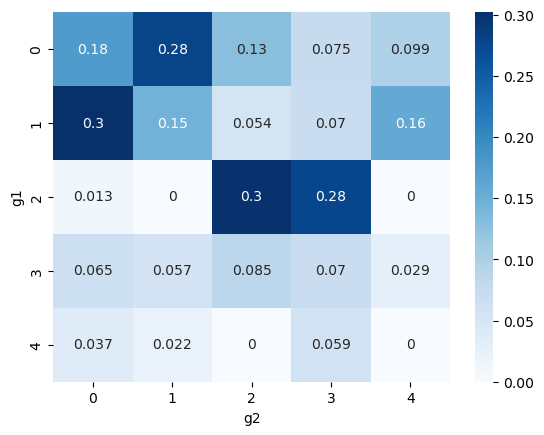

In [195]:
report, g1_clusters, g2_clusters = cluster_similarity_report(g1, g2, n_clusters_g1, n_clusters_g2, labels1, labels2)
ax = sns.heatmap(report, annot=True, cmap='Blues')
ax.set_xlabel('g2')
ax.set_ylabel('g1')

In [173]:
g1_n = 2
g2_n = 2
g1_members = sorted(g1_clusters[g1_n])
g2_members = sorted(g2_clusters[g2_n])
all_unique_members = set(g1_members+g2_members)
df = pd.DataFrame(columns=['g1', 'g2'], index=list(all_unique_members))
for member in all_unique_members:
    df.loc[member, 'g1'] = 'x' if member in g1_members else ''
    df.loc[member, 'g2'] = 'x' if member in g2_members else ''
pd.options.display.max_rows = 999
df[(df['g1']=='x') & (df['g2']=='x')]
#df

,g1,g2
fiji,x,x
philippines,x,x
indonesia,x,x
northkorea,x,x
palau,x,x
newzealand,x,x
india,x,x
micronesia,x,x
usa,x,x
japan,x,x


Text(50.722222222222214, 0.5, 'g2')

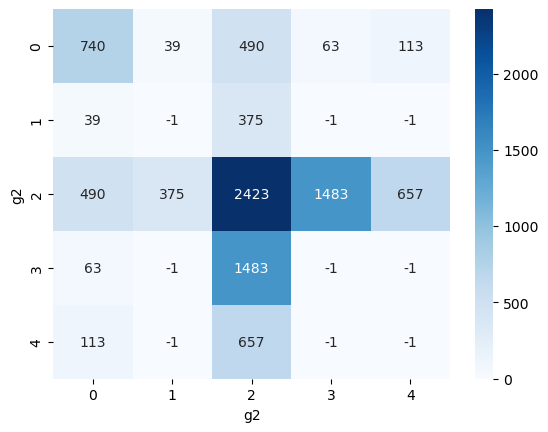

In [196]:
# Avg flow between cntrs in each org cluster
mtx = np.ones((n_clusters_g2, n_clusters_g2))*-1
for i, cluster1 in enumerate(g2_clusters):
    for j, cluster2 in enumerate(g2_clusters):
        done = nx.Graph()
        summ = 0
        cnt = 0
        for country1 in cluster1:
            for country2 in cluster2:
                if country1 != country2 and done.get_edge_data(country1, country2) is None:
                    done.add_edge(country1, country2, weight=1)
                    if g1.get_edge_data(country1, country2):
                        summ += g1.get_edge_data(country1, country2)['weight']
                        cnt += 1
        if cnt != 0:
            mtx[i, j] = summ/cnt
mtx = np.round(mtx)
ax = sns.heatmap(mtx, annot=True, cmap='Blues', fmt='g')
ax.set_xlabel('g2')
ax.set_ylabel('g2')

In [198]:
g2_clusters[0]

{'albania',
 'armenia',
 'austria',
 'azerbaijan',
 'belarus',
 'belgium',
 'bosnia',
 'bulgaria',
 'croatia',
 'cyprus',
 'czechia',
 'denmark',
 'estonia',
 'finland',
 'france',
 'georgia',
 'germany',
 'greece',
 'hungary',
 'iceland',
 'ireland',
 'israel',
 'italy',
 'kazakhstan',
 'kyrgyzstan',
 'latvia',
 'liechtenstein',
 'lithuania',
 'luxembourg',
 'malta',
 'moldova',
 'montenegro',
 'netherlands',
 'northmacedonia',
 'norway',
 'poland',
 'portugal',
 'romania',
 'russia',
 'sanmarino',
 'slovakia',
 'slovenia',
 'spain',
 'sweden',
 'switzerland',
 'tajikistan',
 'turkey',
 'turkmenistan',
 'uk',
 'ukraine',
 'uzbekistan'}